In [6]:
# wavelength interpolation

import dLux as dl
import jax.numpy as np
import jax
import matplotlib.pyplot as plt
import dLux.utils as dlu
from dLux.sources import Source
from jax import Array
from dLux.sources import BaseSource
from jax import vmap
import jax.random as jr
from dLux import spectra
from matplotlib.style import use
use('default')
jax.config.update("jax_enable_x64", True)
plt.rcParams['image.origin'] = 'lower'

from jax.scipy.special import gammaln, xlogy

def poisson_loglike_gamma(k, mu):
    # analytic continuation using gammaln(k+1)
    k = np.asarray(k, dtype=float)
    mu = np.asarray(mu, dtype=float)
    valid = (k >= 0) & np.isfinite(k) & (mu > 0) & np.isfinite(mu)
    logp = xlogy(k, mu) - mu - gammaln(k + 1.0)
    return np.where(valid, logp, -np.inf)

# define the likelihood function:
def poiss_loglike(pytree, data) -> float:
    """
    Poissonian log likelihood of the pytree given the data. Assumes the pytree
    has a .model() function.

    Parameters
    ----------
    pytree : Base
        Pytree with a .model() function.
    data : Array
        Data to compare the model to.

    Returns
    -------
    log_likelihood : Array
        Log likelihood of the pytree given the data.
    """
    return poisson_loglike_gamma(pytree.model(), data).sum()

def normal_logpdf(x, mu, sigma):
    z = (x-mu)/sigma
    return -0.5 * (np.log(2*np.pi) + 2*np.log(sigma) + z**2)


### OPTICA FIGURES: INTEXT FONTSIZE 10. CAPTIONS GENERALLY 8

# latex
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]
import shutil
print(shutil.which("latex"))

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "serif",
#     "text.latex.preamble": r"""
# \usepackage[T1]{fontenc}
# \usepackage{newtxtext,newtxmath}
# """,

#     "font.size": 10,
#     "axes.labelsize": 10,
#     "axes.titlesize": 10,
#     "xtick.labelsize": 10,
#     "ytick.labelsize": 10,
#     "legend.fontsize": 10,
#     "figure.titlesize": 10,
# })

# plt.rcParams["figure.dpi"] = 300
# fig_width = 379.41753 / 72.27 # = 5.25
# fig_width = 5.25

# new style
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"""
\usepackage[T1]{fontenc}
\usepackage{newtxtext,newtxmath}
""",

    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "legend.title_fontsize": 7,
    "figure.titlesize": 7,

    "figure.dpi": 300,
    "savefig.bbox": None,
})

fig_width = 170 / 25.4  # 6.693 inches

/Library/TeX/texbin/latex


In [7]:
eps = 1e-15
class CombinedSpectrum(dl.Spectrum):
    wavelengths: Array
    filt_weights: Array
    basis_weights: Array
    weights: Array
    flux: float

    def __init__(self, wavels, filt_weights, basis_weights):
        self.wavelengths = np.asarray(wavels, dtype=float)
        self.filt_weights = np.asarray(filt_weights, dtype=float)
        self.basis_weights = np.asarray(basis_weights, dtype=float)

        spec_w = self.spec_weights()
        weights = self.filt_weights * spec_w
        self.weights = weights / weights.sum()
        self.flux = np.sum(spec_w)

    def spec_weights(self):
        raise NotImplementedError

    def normalise(self):
        return self


class CombinedBasisSpectrum(CombinedSpectrum):
    basis_vects: Array

    def __init__(self, wavels, filt_weights, basis_weights, basis):
        self.basis_vects = np.asarray(basis, dtype=float)
        super().__init__(wavels, filt_weights, basis_weights)

    def spec_weights(self):
        return np.maximum(np.sum(self.basis_vects * self.basis_weights, axis=1), eps)
        # return 10 ** (np.sum(self.basis_vects * self.basis_weights, axis=1))

In [8]:
from zodiax.diffops import hessian
wf_npixels = 512
diameter = 1.0
wf_oversample = 5

# changing
n_wavels_data = 101

# make a grid from this:
fovs = np.logspace(0, 2, 21) # lambda_min on Ds.
fluxes = np.logspace(4, 10, 21)

nconstrained_grid = np.zeros((len(fovs), len(fluxes)), dtype=int)

def calculate_nconstrained_modes(fov, flux, threshold=0.1):
    wf_npixels = 1024
    diameter = 1.0
    wf_oversample = 5

    n_wavels_data = 101

    # Important: psf_npixels must be an integer
    psf_npixels = int(np.round(2 * fov))

    coords = dlu.pixel_coords(wf_npixels * wf_oversample, diameter)

    primary = dlu.circle(coords, diameter / 2)
    aperture = dlu.combine(np.array([primary]), wf_oversample)

    aperture_layer = dl.TransmissiveLayer(aperture, True)

    layers = [
        (
            'aperture',
            aperture_layer
        )
    ]

    psf_pixel_scale = dlu.rad2arcsec((1.0e-6) / 2)  # nyquist
    oversample = 2

    optics = dl.AngularOpticalSystem(
        wf_npixels=wf_npixels,
        diameter=diameter,
        layers=layers,
        psf_npixels=psf_npixels,
        psf_pixel_scale=psf_pixel_scale,
        oversample=oversample
    )

    wlmin_data = 1.0e-6
    wlmax_data = 2.0e-6

    wavelengths_data = np.linspace(wlmin_data, wlmax_data, n_wavels_data)

    nbasis = n_wavels_data
    bandpass = np.ones(n_wavels_data)

    spectrum_bins = CombinedBasisSpectrum(
        wavelengths_data,
        bandpass,
        np.ones(nbasis),
        np.eye(nbasis)
    )

    source_data = dl.PointSource(
        spectrum=spectrum_bins
    )

    model_data = dl.Telescope(optics, source_data)

    def model_psf(spectrum, instrument):
        old_spec = instrument.get("source.spectrum")

        new_spec = CombinedBasisSpectrum(
            wavels=old_spec.wavelengths,
            filt_weights=old_spec.filt_weights,
            basis_weights=spectrum,
            basis=old_spec.basis_vects,
        )

        telescope = instrument.set("source.spectrum", new_spec)
        telescope = telescope.set("source.flux", telescope.get("source.spectrum").flux)
        return telescope.model()

    injected_spectrum = np.ones(n_wavels_data) / n_wavels_data * flux

    img_full = model_psf(injected_spectrum, model_data)

    def loss_fn(params, model, data):
        spectrum = params['spectrum']
        img = model_psf(spectrum, model)
        loss = -poisson_loglike_gamma(data, img).sum()
        return loss

    params = {
        "spectrum": injected_spectrum
    }

    f = lambda params: loss_fn(params, model_data, img_full)

    H, unflatten = hessian(f, params)

    H = np.asarray(H)
    H = 0.5 * (H + H.T)

    eigvals, eigvecs = np.linalg.eigh(H)

    idx = np.argsort(eigvals)[::-1]

    eigvals = eigvals[idx]
    eigvecs = eigvecs[:, idx]

    # Optional sign convention
    for i in range(eigvecs.shape[0]):
        eigvecs = eigvecs.at[:, i].mul(np.sign(np.mean(eigvecs[:1, i])))

    a = eigvecs.T @ injected_spectrum

    relstd = 1 / (np.abs(a[0]) * np.sqrt(eigvals))

    # safer than np.argmax(relstd > threshold)
    # because np.argmax returns 0 if nothing is True
    bad = np.where(relstd > threshold)[0]

    if len(bad) == 0:
        nconstrained_modes = len(relstd)
    else:
        nconstrained_modes = bad[0]

    return nconstrained_modes

In [9]:
fovs = np.logspace(0,2,21) # lambda_min on Ds.
fluxes = np.logspace(4, 10, 21)
print(fluxes)
print(fovs)

[1.00000000e+04 1.99526231e+04 3.98107171e+04 7.94328235e+04
 1.58489319e+05 3.16227766e+05 6.30957344e+05 1.25892541e+06
 2.51188643e+06 5.01187234e+06 1.00000000e+07 1.99526231e+07
 3.98107171e+07 7.94328235e+07 1.58489319e+08 3.16227766e+08
 6.30957344e+08 1.25892541e+09 2.51188643e+09 5.01187234e+09
 1.00000000e+10]
[  1.           1.25892541   1.58489319   1.99526231   2.51188643
   3.16227766   3.98107171   5.01187234   6.30957344   7.94328235
  10.          12.58925412  15.84893192  19.95262315  25.11886432
  31.6227766   39.81071706  50.11872336  63.09573445  79.43282347
 100.        ]


In [11]:
for i, fov in enumerate(fovs):
    for j, flux in enumerate(fluxes):
        print(f"fov={fov:.2f}, flux={flux:.2e}")

        nconstrained_grid = nconstrained_grid.at[i, j].set(calculate_nconstrained_modes(
            fov=fov,
            flux=flux,
            threshold=0.1
        ))

fov=1.00, flux=1.00e+04
fov=1.00, flux=2.00e+04
fov=1.00, flux=3.98e+04
fov=1.00, flux=7.94e+04
fov=1.00, flux=1.58e+05
fov=1.00, flux=3.16e+05
fov=1.00, flux=6.31e+05
fov=1.00, flux=1.26e+06
fov=1.00, flux=2.51e+06
fov=1.00, flux=5.01e+06
fov=1.00, flux=1.00e+07
fov=1.00, flux=2.00e+07
fov=1.00, flux=3.98e+07
fov=1.00, flux=7.94e+07
fov=1.00, flux=1.58e+08
fov=1.00, flux=3.16e+08
fov=1.00, flux=6.31e+08
fov=1.00, flux=1.26e+09
fov=1.00, flux=2.51e+09
fov=1.00, flux=5.01e+09
fov=1.00, flux=1.00e+10
fov=1.26, flux=1.00e+04
fov=1.26, flux=2.00e+04
fov=1.26, flux=3.98e+04
fov=1.26, flux=7.94e+04
fov=1.26, flux=1.58e+05
fov=1.26, flux=3.16e+05
fov=1.26, flux=6.31e+05
fov=1.26, flux=1.26e+06
fov=1.26, flux=2.51e+06
fov=1.26, flux=5.01e+06
fov=1.26, flux=1.00e+07
fov=1.26, flux=2.00e+07
fov=1.26, flux=3.98e+07
fov=1.26, flux=7.94e+07
fov=1.26, flux=1.58e+08
fov=1.26, flux=3.16e+08
fov=1.26, flux=6.31e+08
fov=1.26, flux=1.26e+09
fov=1.26, flux=2.51e+09
fov=1.26, flux=5.01e+09
fov=1.26, flux=1

In [ ]:
# np.save('nconstrained_grid_2.npy', nconstrained_grid)

In [10]:
nconstrained_grid = np.load("nconstrained_grid_2.npy")

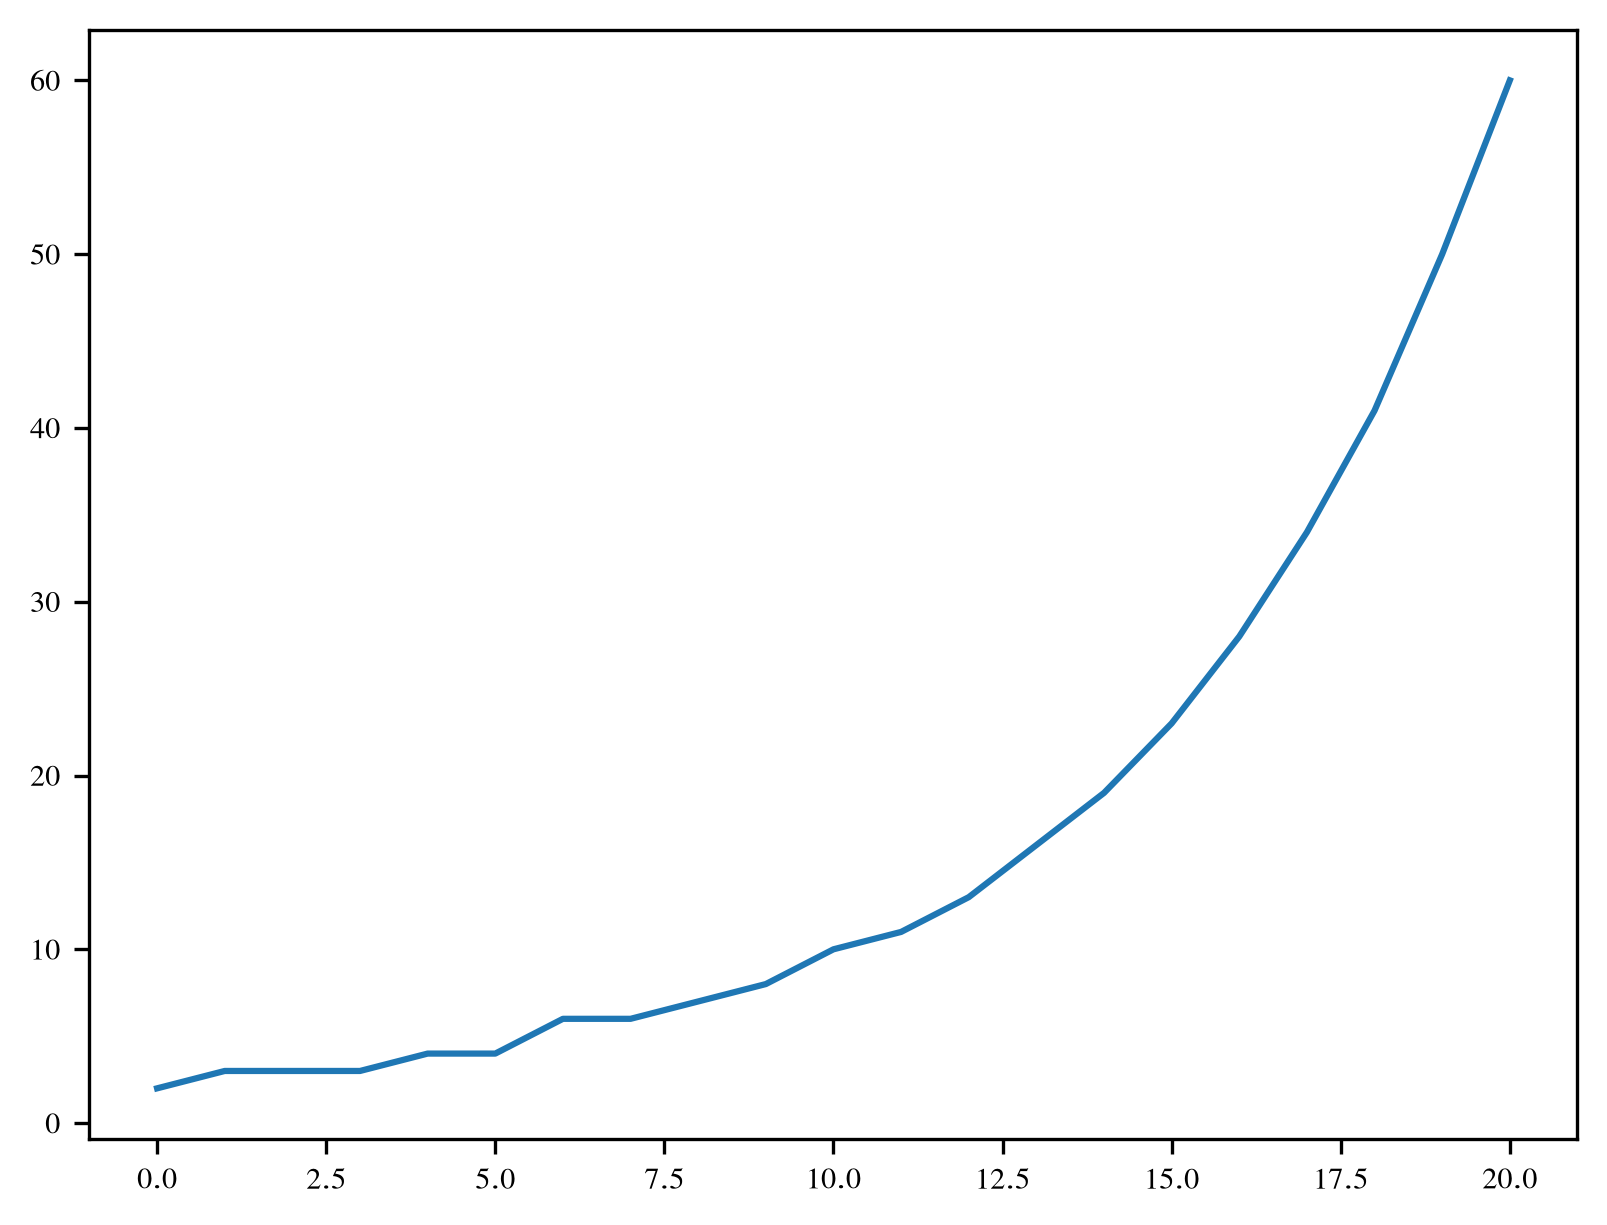

In [11]:
plt.plot(nconstrained_grid[:,10])

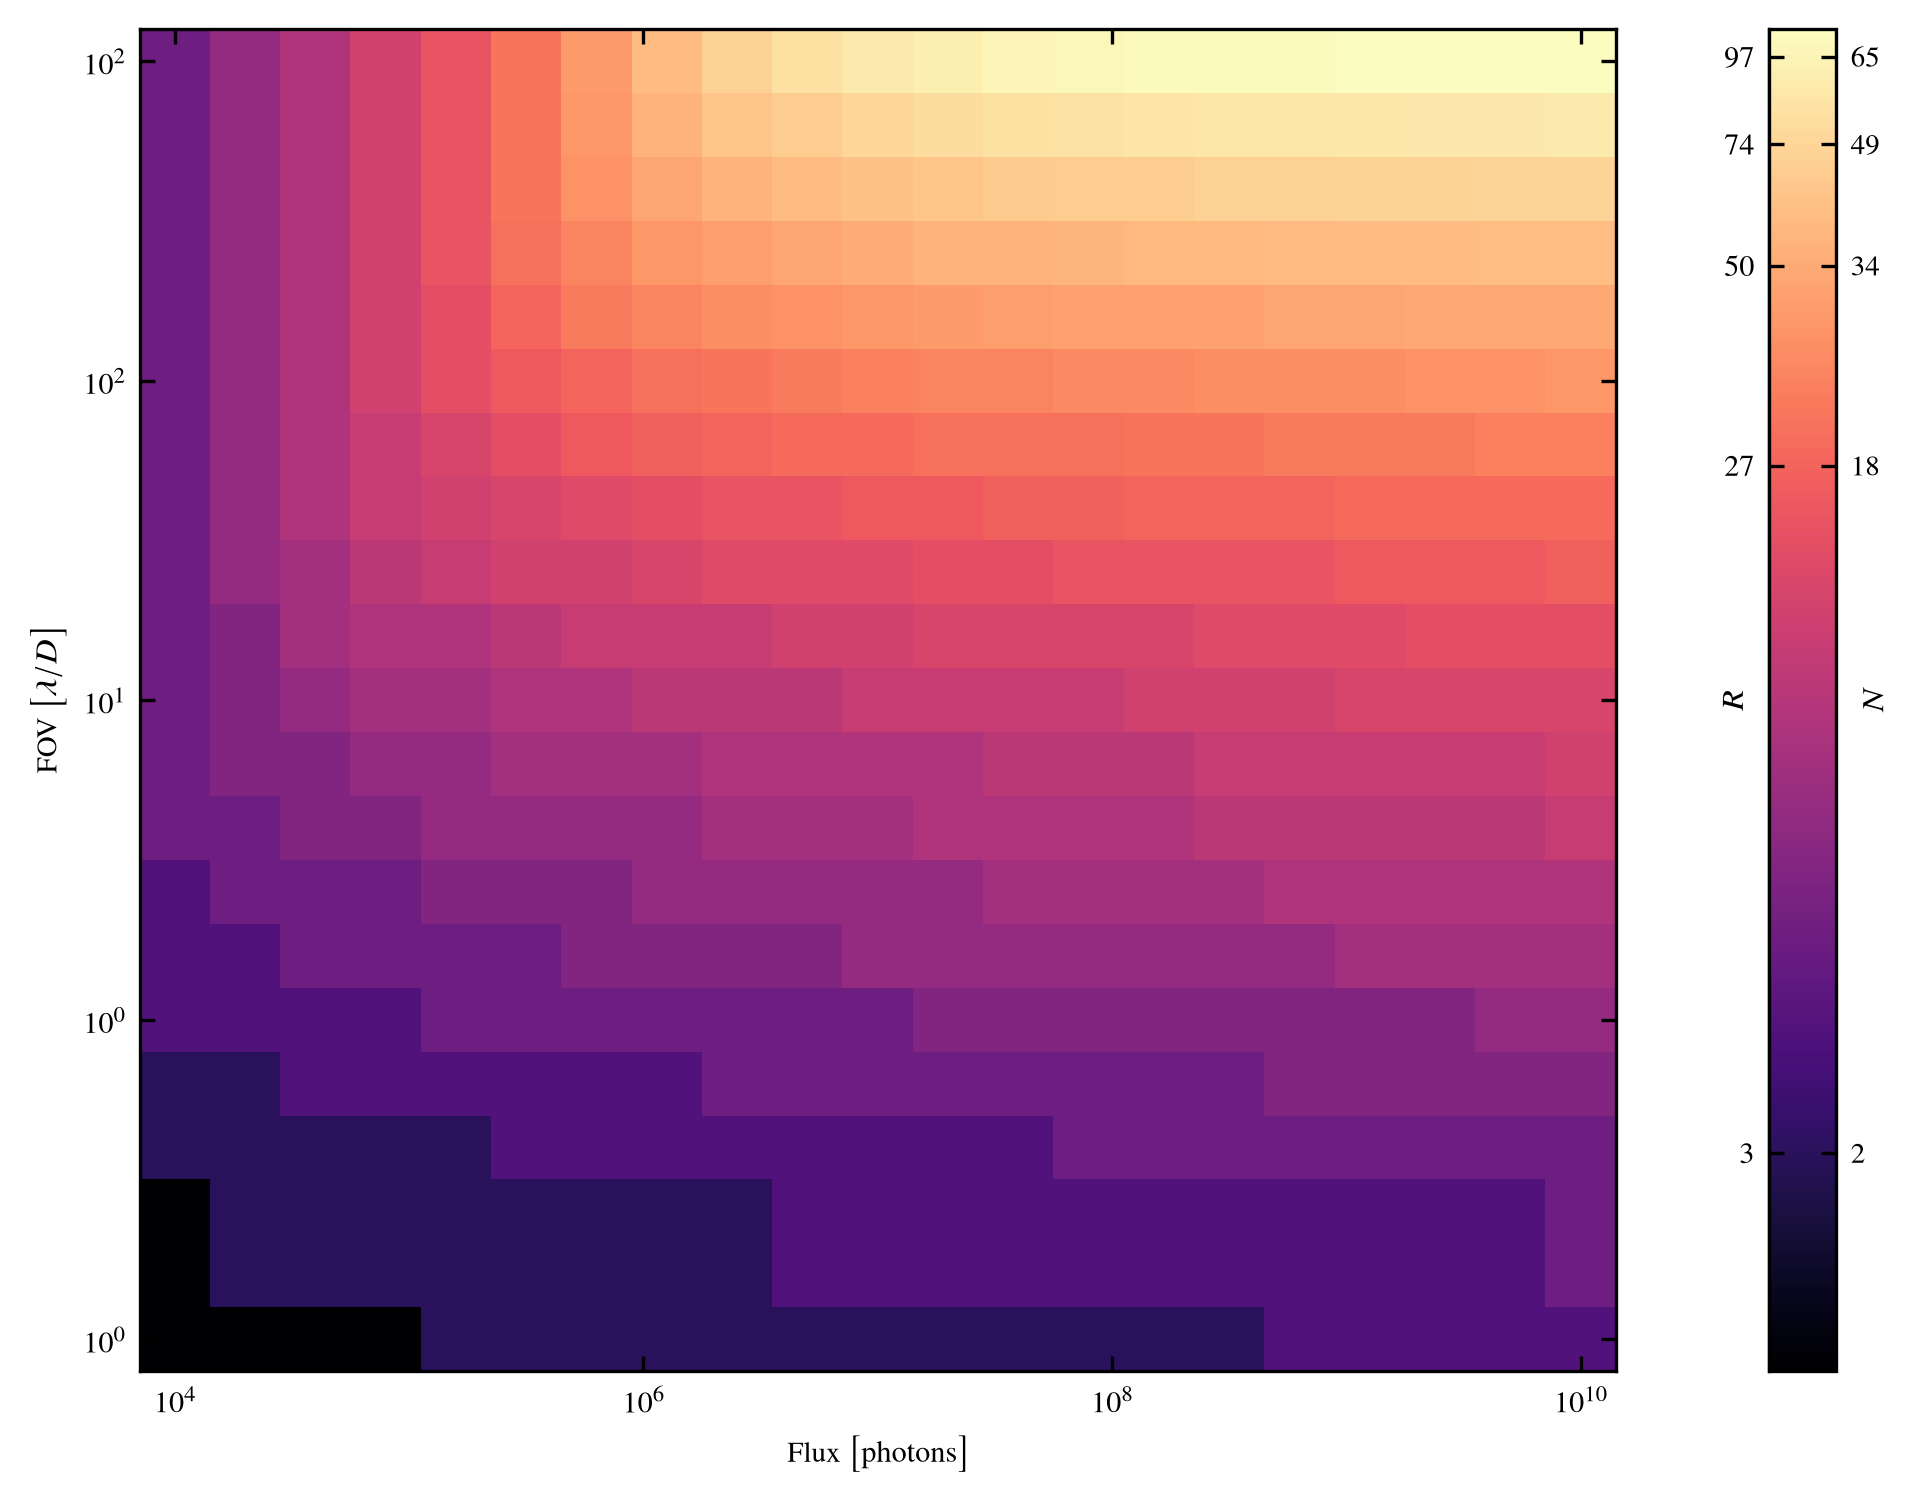

In [12]:
plt.figure(figsize=(fig_width,fig_width*0.75))
# plt.imshow(nconstrained_grid, cmap='magma')

log_fluxes = np.log10(fluxes)
log_fovs = np.log10(fovs)

dlog_flux = np.mean(np.diff(log_fluxes))
dlog_fov = np.mean(np.diff(log_fovs))

plt.imshow(
    np.log10(nconstrained_grid),
    cmap='magma',
    origin='lower',
    aspect='auto',
    interpolation='none',
    extent=[
        log_fluxes[0] - dlog_flux/2,
        log_fluxes[-1] + dlog_flux/2,
        log_fovs[0] - dlog_fov/2,
        log_fovs[-1] + dlog_fov/2,
    ]
)

plt.xlabel(r'Flux $\bigl[ \mathrm{photons} \bigr]$')
plt.ylabel(r'FOV $\bigl[\lambda/D\bigr]$')
plt.tick_params(
    direction='in',
    right=True,
    top=True
)

xticks = np.arange(4, 10.01, 2)   

plt.xticks(
    xticks,
    [fr'$10^{{{t:.0f}}}$' for t in xticks]
)

yticks = np.arange(0, 2.01, 0.5)

plt.yticks(
    yticks,
    [fr'$10^{{{t:.0f}}}$' for t in yticks],
    rotation=0
)


cbar = plt.colorbar(label=r'$N$',
                    pad=0.08,)
cbar.ax.tick_params(direction='in',
                    left=True)
cbar.set_label(r'$N$', labelpad=-4)

N_ticks = np.log10(np.linspace(np.min(nconstrained_grid)+1, np.max(nconstrained_grid)-6, 5))
R_ticks = round(10**N_ticks * (1.5e-6)/1e-6)  # your conversion here

cbar.set_ticks(N_ticks)
N_tick_labels = round((10**N_ticks))
cbar.set_ticklabels(N_tick_labels)

secax = cbar.ax.secondary_yaxis(
    'left',
    functions=(lambda x: x, lambda x: x)
)

secax.set_yticks(N_ticks)
secax.set_yticklabels([fr'${r:g}$' for r in R_ticks])
secax.set_ylabel(r'$R$',labelpad=-6)
secax.tick_params(direction='in')

plt.tight_layout()
plt.subplots_adjust(right=1.025)
# plt.savefig('R_matrix_log_viridis.pdf',dpi=300)
plt.show()

In [13]:
# one giant very big plot
# need the image
wf_npixels = 1024
diameter = 1.0
wf_oversample = 5

n_wavels_data = 101

# Important: psf_npixels must be an integer
psf_npixels = int(np.round(2 * 100))

coords = dlu.pixel_coords(wf_npixels * wf_oversample, diameter)

primary = dlu.circle(coords, diameter / 2)
aperture = dlu.combine(np.array([primary]), wf_oversample)

aperture_layer = dl.TransmissiveLayer(aperture, True)

layers = [
    (
        'aperture',
        aperture_layer
    )
]

psf_pixel_scale = dlu.rad2arcsec((1.0e-6) / 2)  # nyquist
oversample = 2

optics = dl.AngularOpticalSystem(
    wf_npixels=wf_npixels,
    diameter=diameter,
    layers=layers,
    psf_npixels=psf_npixels,
    psf_pixel_scale=psf_pixel_scale,
    oversample=oversample
)

wlmin_data = 1.0e-6
wlmax_data = 2.0e-6

wavelengths_data = np.linspace(wlmin_data, wlmax_data, n_wavels_data)

nbasis = n_wavels_data
bandpass = np.ones(n_wavels_data)

spectrum_bins = CombinedBasisSpectrum(
    wavelengths_data,
    bandpass,
    np.ones(nbasis),
    np.eye(nbasis)
)

source_data = dl.PointSource(
    spectrum=spectrum_bins
)

model_data = dl.Telescope(optics, source_data)

def model_psf(spectrum, instrument):
    old_spec = instrument.get("source.spectrum")

    new_spec = CombinedBasisSpectrum(
        wavels=old_spec.wavelengths,
        filt_weights=old_spec.filt_weights,
        basis_weights=spectrum,
        basis=old_spec.basis_vects,
    )

    telescope = instrument.set("source.spectrum", new_spec)
    telescope = telescope.set("source.flux", telescope.get("source.spectrum").flux)
    return telescope.model()

injected_spectrum = np.ones(n_wavels_data) / n_wavels_data * 1e10

img_full = model_psf(injected_spectrum, model_data)

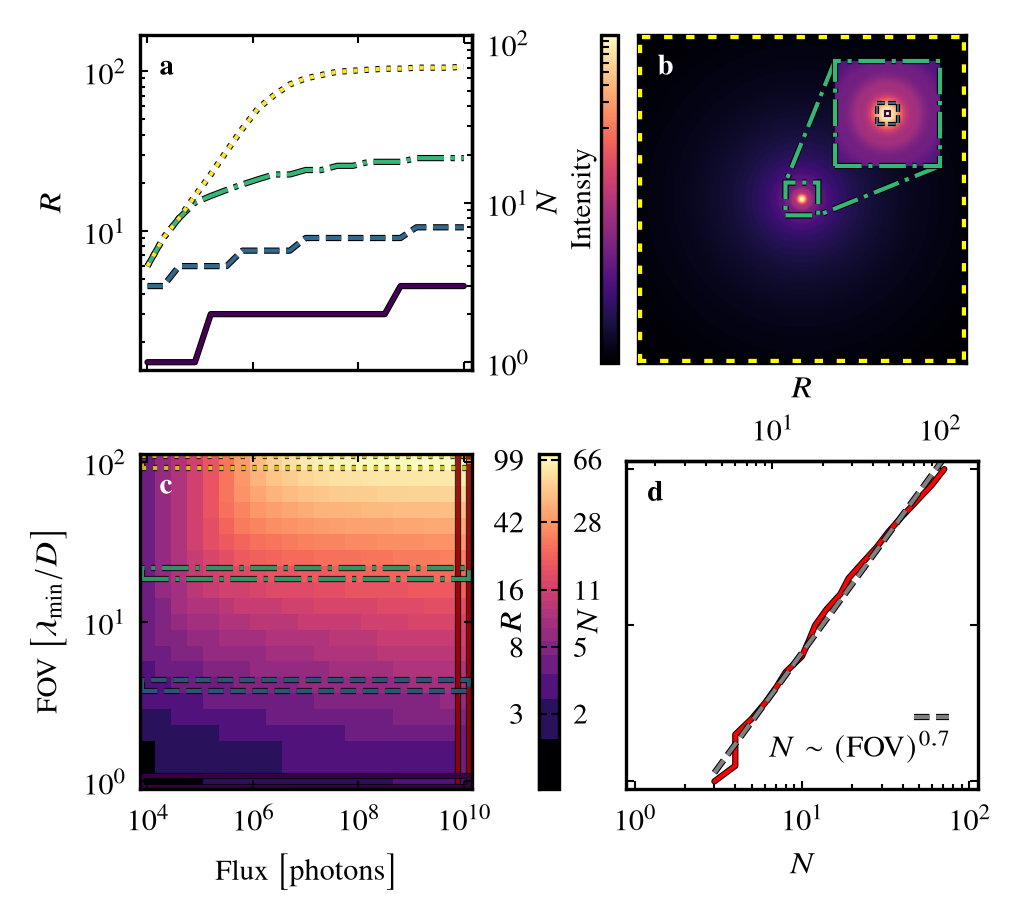

In [38]:
# DISCRETISED COLORBAR VERSION
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.gridspec import GridSpec
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle

path_effects = [pe.Stroke(linewidth=1.5, foreground='k'), pe.Normal()]

# from cycler import cycler

# setting tick sizes
plt.rcParams['xtick.major.size'] = 2.0
plt.rcParams['ytick.major.size'] = 2.0

plt.rcParams['xtick.major.width'] = 0.5
plt.rcParams['ytick.major.width'] = 0.5

plt.rcParams['xtick.minor.width'] = 0.5
plt.rcParams['ytick.minor.width'] = 0.5

plt.rcParams['xtick.minor.size'] = 1.25
plt.rcParams['ytick.minor.size'] = 1.25

# setting colors
plt.rcParams['lines.linewidth'] =  1.0
plt.rcParams['lines.solid_capstyle'] = 'round'
plt.rcParams['legend.frameon'] = False
plt.rcParams['legend.handlelength'] = 1.0
plt.rcParams['legend.handletextpad'] = 0.4

# fig = plt.figure(figsize=(fig_width, fig_width*0.9))

# # adjustment... chopped
# fig.subplots_adjust(
#     left=0.12,
#     right=0.98,
#     bottom=0.12,
#     top=0.98,
# )

# gs = GridSpec(
#     2, 2,
#     figure=fig,
#     height_ratios=[1.0, 1.0],
#     width_ratios=[1.0, 1.0],
#     hspace=0.0,
#     wspace=0.0
# )

# left_gs = gs[:, 0].subgridspec(
#     2, 2,
#     height_ratios=[1.0, 1.0],
#     width_ratios=[1.0, 0.06],  # second column reserved for colorbar
#     hspace=0.25,
#     wspace=0.3,
# )

# right_gs = gs[:, 1].subgridspec(
#     2, 2,
#     height_ratios=[1.0, 1.0],
#     width_ratios=[0.06, 1.0],  # colorbar column LEFT, plot/image column RIGHT
#     hspace=0.25,
#     wspace=0.3,
# )
fig_width_single = 82.5 / 25.4


fig = plt.figure(
    figsize=(fig_width_single, fig_width_single * 0.9),
    layout="none",
)

fig.subplots_adjust(
    left=0.12,   # was 0.12
    right=0.98,
    bottom=0.12, # was 0.12
    top=0.98,
)

gs = GridSpec(
    2, 2,
    figure=fig,
    height_ratios=[1, 1],
    width_ratios=[1, 1],
    hspace=0,
    wspace=0,
)

left_gs = gs[:, 0].subgridspec(
    2, 2,
    height_ratios=[1, 1],
    width_ratios=[1, 0.06],
    hspace=0.25,  # was 0.25
    wspace=0.38,  # was 0.30
)

right_gs = gs[:, 1].subgridspec(
    2, 2,
    height_ratios=[1, 1],
    width_ratios=[0.06, 1],
    hspace=0.3,
    wspace=0.25,
)


plt.subplot(left_gs[1, 0])
log_fluxes = np.log10(fluxes)
log_fovs = np.log10(fovs)

dlog_flux = np.mean(np.diff(log_fluxes))
dlog_fov = np.mean(np.diff(log_fovs))

Nmin = int(np.min(nconstrained_grid))
Nmax = int(np.max(nconstrained_grid))

# integer values
N_vals = np.arange(Nmin, Nmax + 1)

# centres in log-space
log_centres = np.log10(N_vals)

# boundaries halfway between neighbouring log-centres
log_bounds_inner = 0.5 * (log_centres[:-1] + log_centres[1:])

# extrapolate outer boundaries symmetrically in log-space
first_bound = log_centres[0] - (log_bounds_inner[0] - log_centres[0])
last_bound  = log_centres[-1] + (log_centres[-1] - log_bounds_inner[-1])
log_bounds = np.concatenate([np.asarray([first_bound]), log_bounds_inner, np.asarray([last_bound])])

# sample the parent colormap at the log-centres
base_cmap = plt.get_cmap('magma')
u = (log_centres - log_centres[0]) / (log_centres[-1] - log_centres[0])
cmap = ListedColormap(base_cmap(u))

norm = BoundaryNorm(log_bounds, cmap.N)

im = plt.imshow(
    np.log10(nconstrained_grid),
    cmap=cmap,
    norm=norm,
    origin='lower',
    aspect='auto',
    interpolation='auto',
    extent=[
        log_fluxes[0] - dlog_flux/2,
        log_fluxes[-1] + dlog_flux/2,
        log_fovs[0] - dlog_fov/2,
        log_fovs[-1] + dlog_fov/2,
    ]
)

# adding text
ax = plt.gca()
ax.text(
    0.06, 0.94,
    r'\textbf{c}',
    transform=ax.transAxes,
    ha='left',
    va='top',
    color='white',
)

# horizontal lines
# Coluring the lines
cmap2 = plt.get_cmap('viridis')
cols = cmap2(np.linspace(0, 1, 4))

path_effects_05 = [pe.Stroke(linewidth=1.5, foreground='k', alpha=0.8), pe.Normal()]

# vertical rectangle
x0_vert = log_fluxes[-1] - dlog_flux/2 * 0.7
width_vert = dlog_flux * 0.7

y0_vert = log_fovs[0] - dlog_fov/2 * 0.7
y1_vert = log_fovs[-1] + dlog_fov/2 * 0.7
height_vert = y1_vert - y0_vert

rect_vert = Rectangle(
    (x0_vert, y0_vert),
    width_vert,
    height_vert,
    facecolor='none',
    edgecolor='red',
    linestyle='-',
    alpha=0.5,
    path_effects=path_effects_05
)

plt.gca().add_patch(rect_vert)


idxs = [0, 6, 13, 20]

x0 = log_fluxes[0] - dlog_flux/2 * 0.7
x1 = log_fluxes[-1] + dlog_flux/2 * 0.7
width = x1 - x0
linestyles = ['-', '--', '-.', ':']

for idx, col, ls in zip(idxs, cols, linestyles):
    y0 = log_fovs[idx] - dlog_fov/2 * 0.7
    height = dlog_fov * 0.7

    rect = Rectangle(
        (x0, y0),
        width,
        height,
        facecolor='none',
        edgecolor=col,
        # linewidth=1.5,
        linestyle=ls,
        alpha=0.8,
        path_effects=path_effects_05
    )

    plt.gca().add_patch(rect)



plt.xlabel(r'Flux $\bigl[\mathrm{photons}\bigr]$')
plt.ylabel(r'FOV $\bigl[\lambda_{\min}/D\bigr]$')
plt.tick_params(direction='in', right=True, top=True)

xticks = np.arange(4, 10.01, 2)
plt.xticks(xticks, [fr'$10^{{{t:.0f}}}$' for t in xticks])

yticks = np.arange(0, 2.01, 1.0)
plt.yticks(yticks, [fr'$10^{{{t:.0f}}}$' for t in yticks], rotation=0)

# choose displayed ticks on the colorbar
N_tick_labels = np.unique(np.round(np.geomspace(Nmin+1, Nmax-5, 5)).astype(int))
N_tick_labels = N_tick_labels[(N_tick_labels >= Nmin) & (N_tick_labels <= Nmax)]
N_tick_pos = np.log10(N_tick_labels)

cax = plt.subplot(left_gs[1, 1])
cbar = plt.colorbar(
    im,
    cax=cax,
    pad=0.15,
    boundaries=log_bounds,
    spacing='proportional',   # important
    ticks=N_tick_pos
)

# remove the many boundary/minor ticks
from matplotlib.ticker import NullLocator
cbar.ax.yaxis.set_minor_locator(NullLocator())
cbar.ax.tick_params(which='minor', right=False, left=False)

# main ticks
cbar.ax.tick_params(direction='in', left=True)
cbar.set_label(r'$N$', labelpad=-6)
cbar.set_ticklabels(N_tick_labels)

secax = cbar.ax.secondary_yaxis(
    'left',
    functions=(lambda x: x, lambda x: x)
)

R_ticks = np.round(N_tick_labels * (1.5e-6)/1e-6).astype(int)
secax.set_yticks(N_tick_pos)
secax.set_yticklabels([fr'${r:g}$' for r in R_ticks])
secax.set_ylabel(r'$R$', labelpad=-8)
secax.tick_params(direction='in')

plt.subplot(left_gs[0, 0])  # top-left line plot
N_axis_ticks = 10**yticks
N_axis_min = 10**(yticks[0] - dlog_fov/2)
N_axis_max = 10**(yticks[-1] + dlog_fov/2)
R_axis_ticks = 1.5 * N_axis_ticks

plt.loglog(fluxes, 1.5*nconstrained_grid[0, :],  color=cols[0], path_effects=path_effects, ls='-')
plt.loglog(fluxes, 1.5*nconstrained_grid[6, :],  color=cols[1], path_effects=path_effects, ls='--')
plt.loglog(fluxes, 1.5*nconstrained_grid[13, :], color=cols[2], path_effects=path_effects, ls='-.')
plt.loglog(fluxes, 1.5*nconstrained_grid[20, :], color=cols[3], path_effects=path_effects, ls=':')

plt.ylabel(r'$R$')
# plt.minorticks_off()

xmin = 10**(log_fluxes[0] - dlog_flux/2)
xmax = 10**(log_fluxes[-1] + dlog_flux/2)
plt.xlim(xmin, xmax)

# N axis should follow the FOV-style formalism:
# ticks at 10^0.0, 10^0.5, ..., 10^2.0
N_tick_exp = np.arange(0, 2.01, 1.0)
N_ticks = 10**N_tick_exp

# padded N-limits, exactly analogous to the FOV axis
Nmin_plot = 10**(N_tick_exp[0]  - dlog_fov/2)
Nmax_plot = 10**(N_tick_exp[-1] + dlog_fov/2)

# primary axis is R, so convert N-limits to R-limits
plt.ylim(1.5*Nmin_plot, 1.5*Nmax_plot)

# left axis: actual R ticks, not N-mapped ticks
R_tick_exp = np.arange(1.0, 2.01, 1.0)
R_ticks = 10**R_tick_exp

plt.yticks(
    R_ticks,
    [fr'$10^{{{t:.0f}}}$' for t in R_tick_exp]
)

plt.xticks(10**xticks, [])

plt.tick_params(direction='in', right=False, top=True)
plt.tick_params(axis='y', which='minor', direction='in')

# right axis: actual N ticks, mapped through R = 1.5 N
ax = plt.gca()

# adding text
ax.text(
    0.06, 0.94,
    r'\textbf{a}',
    transform=ax.transAxes,
    ha='left',
    va='top',
    color='black'
)


secay = ax.secondary_yaxis(
    'right',
    functions=(lambda R: R/1.5, lambda N: 1.5*N)
)

secay.set_yticks(N_ticks)
secay.set_yticklabels([fr'$10^{{{t:.0f}}}$' for t in N_tick_exp])
secay.set_ylabel(r'$N$', labelpad=2.0)
# secay.minorticks_off()
secay.tick_params(direction='in')
secay.tick_params(which='minor', direction='in')


plt.subplot(right_gs[1, 1])  # bottom-right line plot

x = nconstrained_grid[:, 20]
y = fovs

m, b = np.polyfit(np.log10(x), np.log10(y), 1)

xfit = np.logspace(np.log10(x.min()), np.log10(x.max()), 100)
yfit = 10**b * xfit**m

plt.loglog(x, y, path_effects=path_effects, color='red' )#label=r'$\mathrm{Flux} = 10^{10}$')
A = (10**b)**(-1/m)
M = 1/m
plt.loglog(xfit, yfit, ls='--', color='grey', path_effects=path_effects, label=rf'$N \sim (\mathrm{{FOV}})^{{{M:.1f}}}$')
#legend = plt.legend(loc='lower right', markerfirst=False, bbox_to_anchor=(1.02, 0.05))

ax = plt.gca()
# text
ax.text(
    0.92, 0.08,
    rf'$N \sim (\mathrm{{FOV}})^{{{M:.1f}}}$',
    transform=ax.transAxes,
    ha='right',
    va='bottom',
    size=7.0
)

# line above / beside it
ax.plot(
    [0.82, 0.92],
    [0.22, 0.22],
    transform=ax.transAxes,
    ls='--',
    color='grey',
    path_effects=path_effects,
    clip_on=False
)

# adding text

ax.text(
    0.06, 0.94,
    r'\textbf{d}',
    transform=ax.transAxes,
    ha='left',
    va='top',
    color='black'
)


# print(m)
# plt.loglog(nconstrained_grid[:,15], y, path_effects=path_effects)


plt.xlabel(r'$N$')
# plt.minorticks_off()

# y-axis: same as before, aligned with FOV axis
ymin = 10**(log_fovs[0] - dlog_fov/2)
ymax = 10**(log_fovs[-1] + dlog_fov/2)
plt.ylim(ymin, ymax)

plt.yticks(
    10**yticks,
    []
)
# plt.minorticks_off()
# bottom N-axis should follow FOV formalism: 10^0.0 to 10^2.0, padded
N_tick_exp = np.arange(0, 2.01, 1.0)
N_ticks = 10**N_tick_exp

Nmin_plot = 10**(N_tick_exp[0]  - dlog_fov/2)
Nmax_plot = 10**(N_tick_exp[-1] + dlog_fov/2)

plt.xlim(Nmin_plot, Nmax_plot)

plt.xticks(
    N_ticks,
    [fr'$10^{{{t:.0f}}}$' for t in N_tick_exp]
)

plt.tick_params(direction='in', right=True, top=False)

# top R-axis: actual R values, with R = 1.5 N
ax = plt.gca()

secax = ax.secondary_xaxis(
    'top',
    functions=(lambda N: 1.5*N, lambda R: R/1.5)
)

# actual R ticks, not N-mapped tick labels
R_tick_exp = np.arange(1.0, 2.01, 1.0)
R_ticks = 10**R_tick_exp

secax.set_xticks(R_ticks)
secax.set_xticklabels([fr'$10^{{{t:.0f}}}$' for t in R_tick_exp])
secax.set_xlabel(r'$R$')
# secax.minorticks_off()
secax.tick_params(direction='in')
secax.tick_params(axis='x', which='minor', direction='in')
ax.tick_params(axis='x', which='minor', direction='in')
ax.tick_params(axis='y', which='minor', left=False)

plt.subplot(right_gs[1, 0])

plt.axis('off')

ax_img = plt.subplot(right_gs[0, 1])  # top-right image

stretch = 0.125
img_stretched = img_full**stretch

im_img = ax_img.imshow(img_stretched, cmap='magma', origin='lower')
ax_img.set_xticks([])
ax_img.set_yticks([])

ny, nx = img_stretched.shape

# dotted yellow border around full image
pebig = [pe.Stroke(linewidth=3.0, foreground='k'), pe.Normal()]
outer_rect = Rectangle(
    (-0.5, -0.5),   # imshow pixel edges
    nx,
    ny,
    facecolor='none',
    edgecolor='yellow',
    linestyle=':',
    linewidth=2.0,
    path_effects=pebig,
    zorder=5
)
ax_img.add_patch(outer_rect)

cutout_pix = 40
cx = (nx - 1) / 2
cy = (ny - 1) / 2

x0 = cx - cutout_pix / 2
y0 = cy - cutout_pix / 2

path_effects_2 = [pe.Stroke(linewidth=1.5, foreground='k'), pe.Normal()]

# adding text
ax_img.text(
    0.06, 0.94,
    r'\textbf{b}',
    transform=ax_img.transAxes,
    ha='left',
    va='top',
    color='white'
)


# inset axes
axins = ax_img.inset_axes([0.60, 0.60, 0.32, 0.32]) 

axins.imshow(img_stretched, cmap='magma', origin='lower')
axins.set_xlim(x0, x0 + cutout_pix)
axins.set_ylim(y0, y0 + cutout_pix)
axins.set_xticks([])
axins.set_yticks([])

for spine in axins.spines.values():
    spine.set_alpha(0)

inset_border = Rectangle(
    (0, 0),              # lower-left of inset axis
    1, 1,                # full width/height of inset axis
    transform=axins.transAxes,
    facecolor='none',
    edgecolor=cols[2],   # same green
    linestyle='-.',      # normal matplotlib dash-dot
    linewidth=1.0,
    zorder=20,
    clip_on=False,
    path_effects=path_effects_2
)

axins.add_patch(inset_border)
    
ax_img.indicate_inset_zoom(axins, edgecolor=cols[2], alpha=1.0,ls='-.', path_effects=path_effects_2)

pes = [pe.Stroke(linewidth=1.0, foreground='k'), pe.Normal()]
pess = [pe.Stroke(linewidth=0.5, foreground='k'), pe.Normal()]
inner_specs = [
    (8, cols[1], '--', 0.5, pes),  # size in pixels, colour, linestyle
    (2, cols[0], '-', 0.5, pess),
]

for size, col, ls, width, pef in inner_specs:
    rect = Rectangle(
        (cx - size/2, cy - size/2),
        size,
        size,
        facecolor='none',
        edgecolor=col,
        linestyle=ls,
        linewidth=width,
        zorder=7,
        path_effects=pef
    )
    axins.add_patch(rect)


# make the colorbar axis
cax_img = plt.subplot(right_gs[0, 0])

# manually move colorbar closer to image
fig.canvas.draw()  # makes sure positions are resolved

img_pos = ax_img.get_position()

cbar_width = 0.018   # width of colorbar in figure coordinates
cbar_gap = 0.02    # gap between colorbar and image

cax_img.set_position([
    img_pos.x0 - cbar_gap - cbar_width,
    img_pos.y0,
    cbar_width,
    img_pos.height
])

# ticks linearly spaced in original img_full values
img_tick_vals = np.linspace(np.min(img_full), np.max(img_full), 10)

# tick positions transformed into eighth-root plotted space
img_tick_pos = img_tick_vals**stretch

cbar_img = plt.colorbar(
    im_img,
    cax=cax_img,
    ticks=img_tick_pos,
)

# hide labels, keep tick marks
cbar_img.set_ticklabels([])
cbar_img.ax.tick_params(direction='in',left=True,right=False)
cbar_img.set_label('Intensity', labelpad=-15)


# another adjustment.. chopped


plt.savefig('4plots2_newsize.pdf', dpi=300)
plt.show()

In [634]:
2 * fovs[0]

Array(2., dtype=float64)

In [625]:
log_fovs[13]

Array(1.3, dtype=float64)

In [565]:
log_fovs[20]

Array(2., dtype=float64)

In [337]:
yticks

Array([0. , 0.5, 1. , 1.5, 2. ], dtype=float64)

In [249]:
np.unique(np.round(np.geomspace(Nmin+1, Nmax-5, 5)).astype(int))

array([ 2,  5, 11, 28, 66])

In [247]:
66*1.5

99.0

In [233]:
np.min(nconstrained_grid)

Array(1, dtype=int64)

In [185]:
np.linspace(np.min(nconstrained_grid)+1, np.max(nconstrained_grid)-6, 5)

Array([ 2.  , 17.75, 33.5 , 49.25, 65.  ], dtype=float64)

In [ ]:
0,7,14,21

In [198]:
fovs

Array([  1.        ,   1.25892541,   1.58489319,   1.99526231,
         2.51188643,   3.16227766,   3.98107171,   5.01187234,
         6.30957344,   7.94328235,  10.        ,  12.58925412,
        15.84893192,  19.95262315,  25.11886432,  31.6227766 ,
        39.81071706,  50.11872336,  63.09573445,  79.43282347,
       100.        ], dtype=float64)

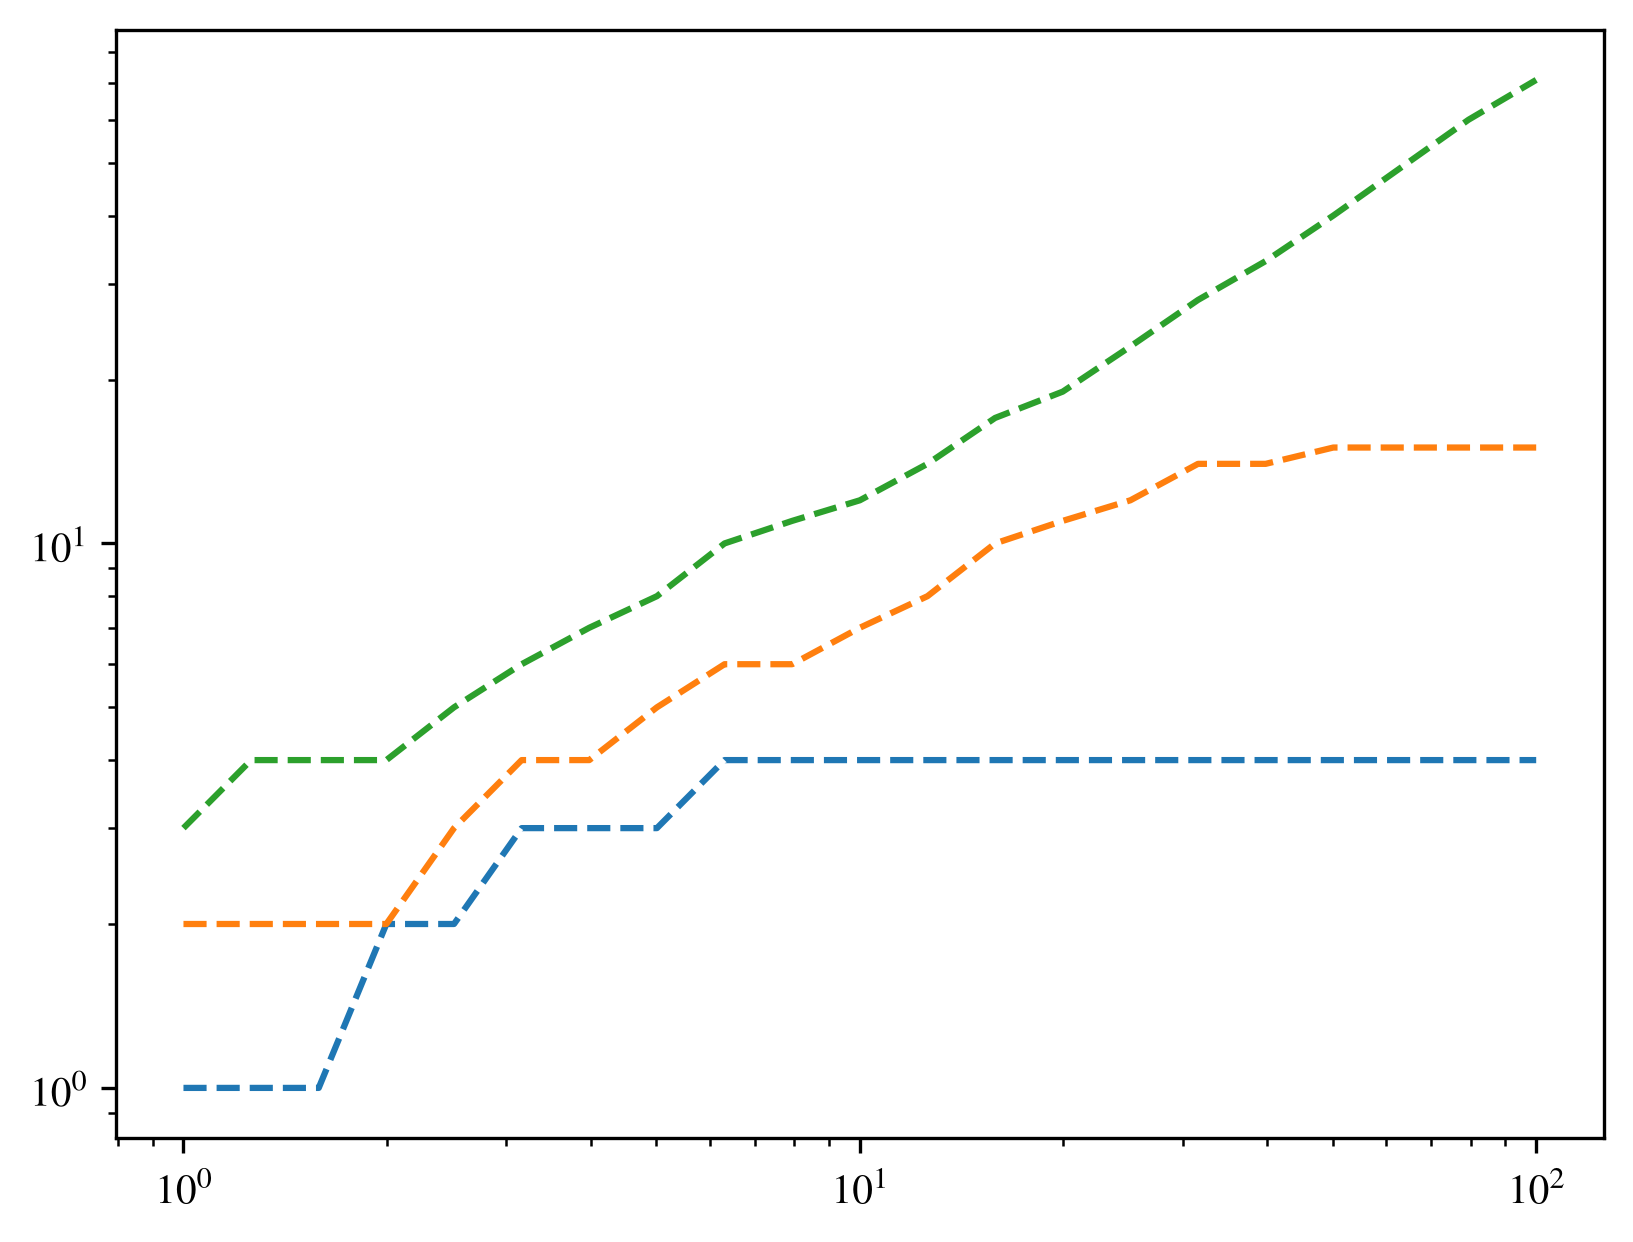

In [ ]:
for i in np.array([0,4,21]):
    plt.loglog(fovs,nconstrained_grid[:,i], ls='--')
    

In [54]:
ytick_labels

['$10^{0\\quad }$',
 '$10^{0.5}$',
 '$10^{1\\quad }$',
 '$10^{1.5}$',
 '$10^{2\\quad }$']

In [45]:
float(yticks[0]).is_integer()

True

In [14]:
plt.imshow(eigvecs)

NameError: name 'eigvecs' is not defined

In [32]:
relstd

NameError: name 'relstd' is not defined

In [28]:
fovs = np.logspace(0,2,31) # lambda_min on Ds.
fluxes = np.logspace(3, 12, 31)
print(fovs)
print(fluxes)

[  1.           1.1659144    1.35935639   1.58489319   1.8478498
   2.15443469   2.51188643   2.92864456   3.41454887   3.98107171
   4.64158883   5.41169527   6.30957344   7.35642254   8.57695899
  10.          11.65914401  13.59356391  15.84893192  18.47849797
  21.5443469   25.11886432  29.28644565  34.14548874  39.81071706
  46.41588834  54.11695265  63.09573445  73.56422545  85.76958986
 100.        ]
[1.00000000e+03 1.99526231e+03 3.98107171e+03 7.94328235e+03
 1.58489319e+04 3.16227766e+04 6.30957344e+04 1.25892541e+05
 2.51188643e+05 5.01187234e+05 1.00000000e+06 1.99526231e+06
 3.98107171e+06 7.94328235e+06 1.58489319e+07 3.16227766e+07
 6.30957344e+07 1.25892541e+08 2.51188643e+08 5.01187234e+08
 1.00000000e+09 1.99526231e+09 3.98107171e+09 7.94328235e+09
 1.58489319e+10 3.16227766e+10 6.30957344e+10 1.25892541e+11
 2.51188643e+11 5.01187234e+11 1.00000000e+12]


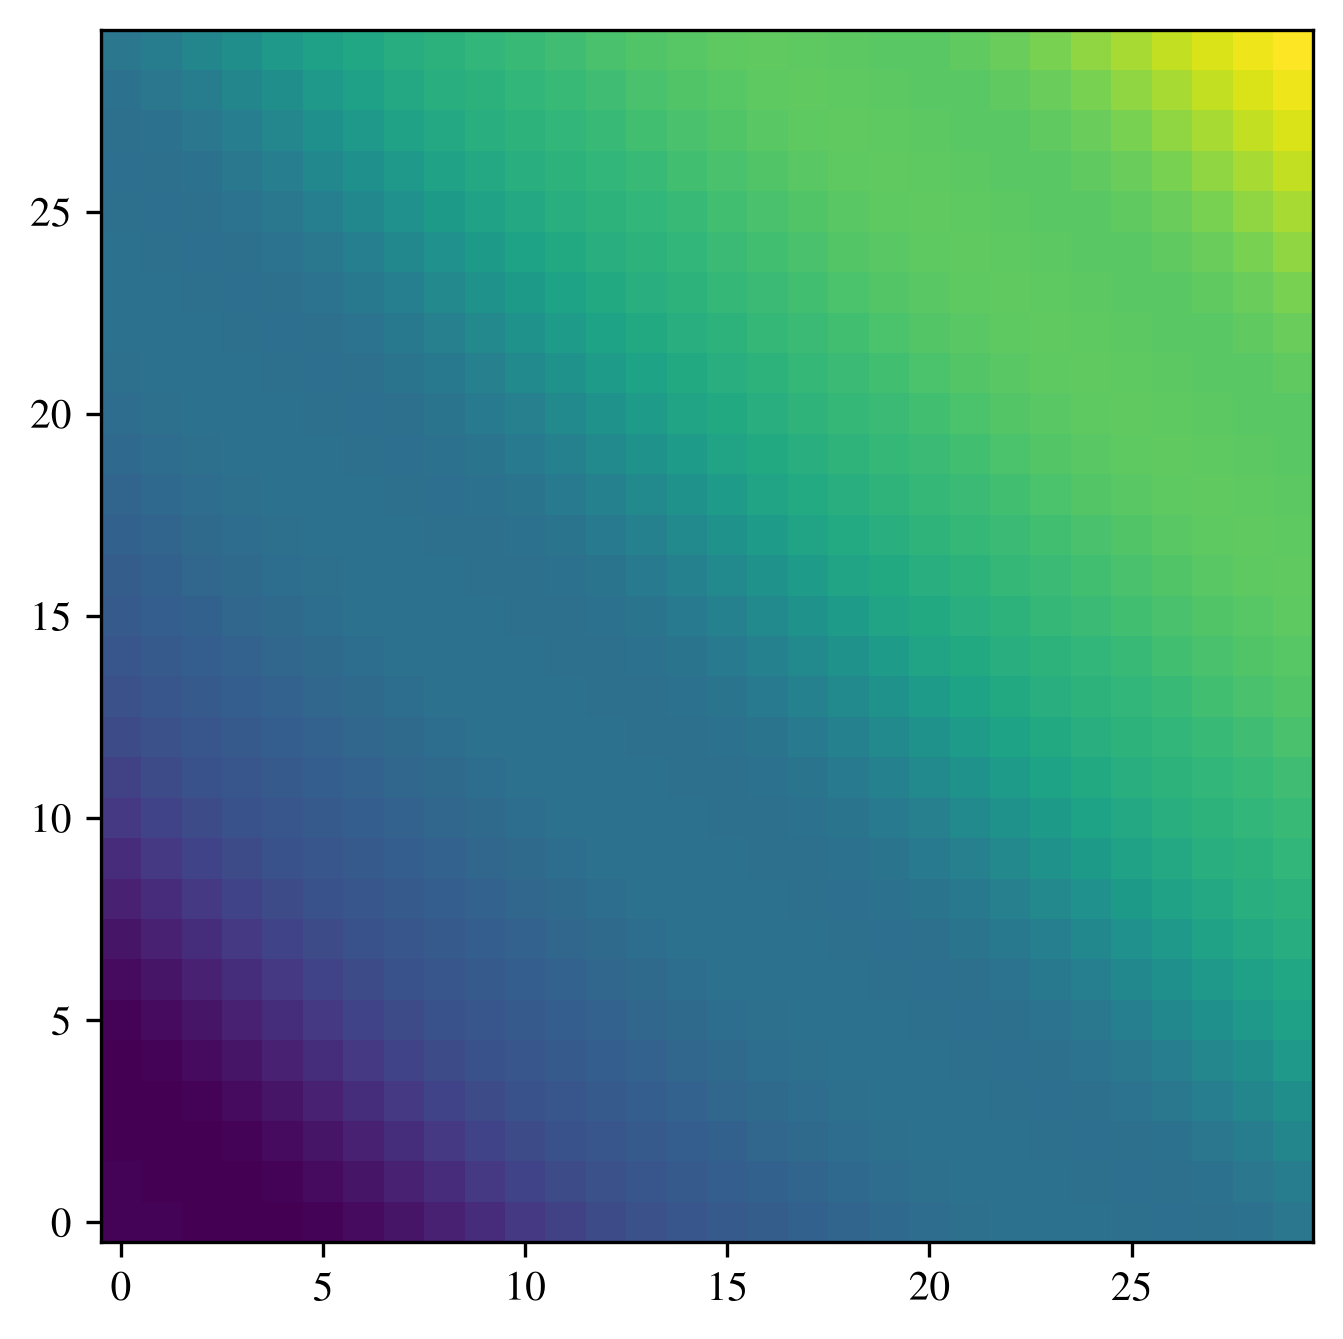

In [31]:
plt.figure(figsize=(fig_width, fig_width))
plt.imshow((img_full**0.01)[:30,:30])